# Lab 1: Gradient Descent

In [ ]:

%matplotlib inline

# import di alcune librerie

import numpy as np
import matplotlib.pyplot as plt

from numpy.linalg import norm # dal package numpy.linalg importo la funzione 'norm'


## Gradient Descent
Definiamo $f : \mathbb{R}^2 \to \mathbb{R}$ come
$$
f(x) =  \frac{1}{2} \left(x_1^2 + \eta x_2^2 \right),
$$
dove $x_i$ denota l'i-esima componente del vettore $x$ e $\eta > 0$.




In [ ]:
def f1(x, eta = 1.0): # definizione di una funzione con nome 'f' che prende due parametri which takes a parameter x
  return 0.5 * (x[0] ** 2 + eta * (x[1] ** 2))

Plottiamo la funzione considerando (ad esempio) $\eta = 1$

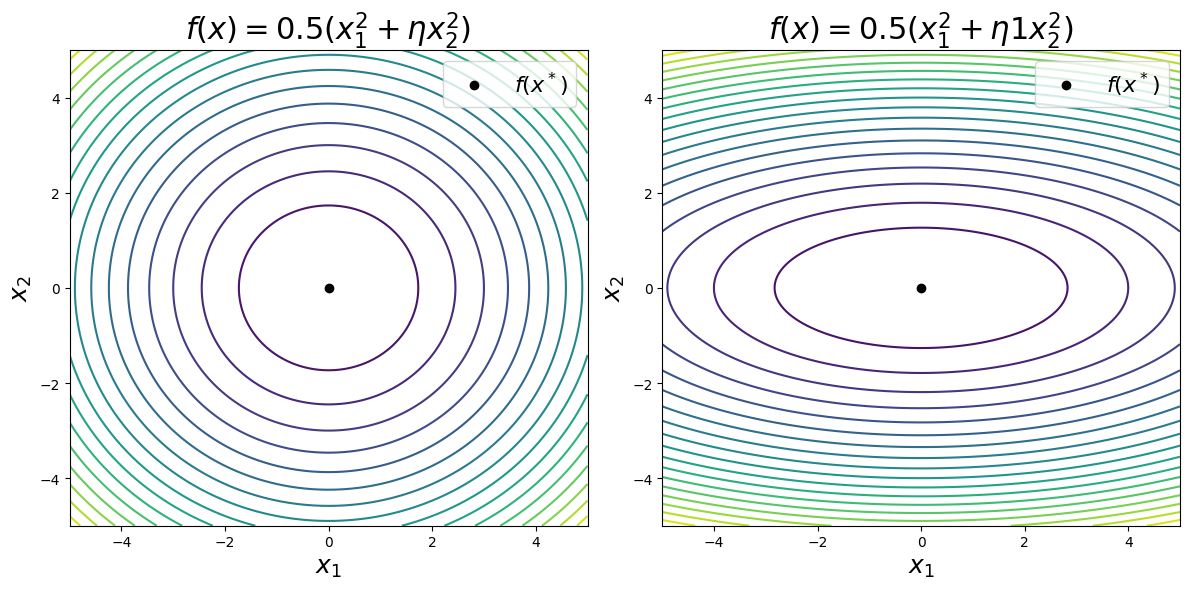

In [ ]:
eta = 1
eta1=5

x1 = np.linspace(-5, 5, 1000)
x2 = np.linspace(-5, 5, 1000)

X1, X2 = np.meshgrid(x1, x2)
Y = (X1 ** 2 + eta * X2 ** 2) / 2
Y1=(X1 ** 2 + eta1 * X2 ** 2) / 2

fig, (ax,ax1) = plt.subplots(1, 2, figsize=(12, 6))
ax.set_title("$f(x) = 0.5 (x_1^2 + \eta x_2^2) $", fontsize=22)
ax.contour(X1, X2, Y, levels=20)
ax.plot(0, 0, 'o', c='black', label="$f(x^*)$")

ax.legend(fontsize=16)
ax.set_xlabel("$x_1$", fontsize=18)
ax.set_ylabel("$x_2$", fontsize=18)
fig.tight_layout()


ax1.set_title("$f(x) = 0.5 (x_1^2 + \eta1 x_2^2) $", fontsize=22)
ax1.contour(X1, X2, Y1, levels=20)
ax1.plot(0, 0, 'o', c='black', label="$f(x^*)$")

ax1.legend(fontsize=16)
ax1.set_xlabel("$x_1$", fontsize=18)
ax1.set_ylabel("$x_2$", fontsize=18)
fig.tight_layout()


Ora, consideriamo seguente problema
$$
x^* \in \arg\min\limits_{x \in \mathbb{R}^2} f(x)
$$
dove $f$ e\` definita sopra. Per risolvere il problema, implementiamo Gradient Descent i.e.
$$
x_{k + 1} = x_k - \gamma \nabla f(x_k)
$$
dove $\gamma$ e\` lo stepsize. Quindi dobbiamo:
- implementare una funzione `grad_f1` che data una $x \in \mathbb{R}^2$ ritorna $\nabla f(x)$.
- calcolare lo step-size $\gamma$

Dato che la funzione target dipende da un parametro $\eta$ e vogliamo essere agnostici rispetto ad esso, la funzione `grad_f1` prendera\` in input due parametri: `x` ed `eta`

In [ ]:
def grad_f1(x, eta = 1.0):
  # TODO: ritorna un numpy array rappresentante il gradiente di f in x
  return np.array((x[0],eta * (x[1])))


Implementiamo ora una funzione `gradient_descent` definita come segue
```
gradient_descent(x0, eta, gamma, max_iters = 10)
```
dove:
- `x0` e\` l'inizializzazione
- `eta` rappresenta il parametro della funzione $\eta$
- `gamma` e\` lo stepsize
- `max_iters` e\` il massimo numero di iterazioni

In [ ]:
def gradient_descent(x0, eta, gamma, max_iters = 10):
  x_obs = np.empty((max_iters, 2)) # matrice di size max_iters x 2. Viene usata per salvare le stime dei minimizzatori (i.e. le iterate)
  f_obs = np.empty(max_iters) # vettore di size max_iters. Viene usato per salvare i valori della funzione sulle iterate (i.e. f(x_k))
  x = x0.copy()
  for k in range(max_iters):
    x_obs[k] = x
    f_obs[k] = f1(x, eta)
    # TODO: computa l'iterazione di gradient descent
    x=x-gamma*grad_f1(x, eta)
  # ritorna l'ultima iterata e la history di tutte le stime e i relativi valori della funzione
  return x, x_obs, f_obs

Ora, data un'inizializzazione, calcoliamo uno step-size $\gamma$ ragionevole ed eseguiamo gradient descent per un certo numero di iterazioni (e.g. 20).

Per scegliere lo step-size, osserviamo che la funzione e\` fortemente convessa e liscia. Quindi possiamo scegliere $\gamma \in (0, 2/L)$. Nello specifico consideriamo la scelta
$$
\gamma = \frac{2}{L + \mu}
$$
dove $\mu$ e\` il parametro di forte convessita ed $L$ e\` la costante di Lipschitz del gradiente.


In [ ]:
x0 = np.array([5.0, 5.0]) # inizializzazione
# TODO: scegli un valore per eta > 1
eta = 5



# TODO: calcola lo stepsize
#dalla teoria mi sono calcolato che:
mu=1
L=eta #dalla teoria so che eta <= L
gamma = 2/(L+mu)
max_iters = 20

# TODO: esegui gradient descent
x, x_obs, f_obs = gradient_descent(x0, eta, gamma, max_iters)

definiamo una funzione per plottare i valori della funzione

In [ ]:
def plot_function_values(f_vals):
  fig, ax = plt.subplots(1, 1, figsize=(10, 7))
  ax.plot(range(f_vals.shape[0]), f_vals, '-', color='black', lw=2, label="$f$")
  ax.set_xlabel("$k$", fontsize=18)
  ax.set_ylabel("$f(x_k)$", fontsize=18)
  ax.set_yscale("log")
  ax.legend(fontsize=18)


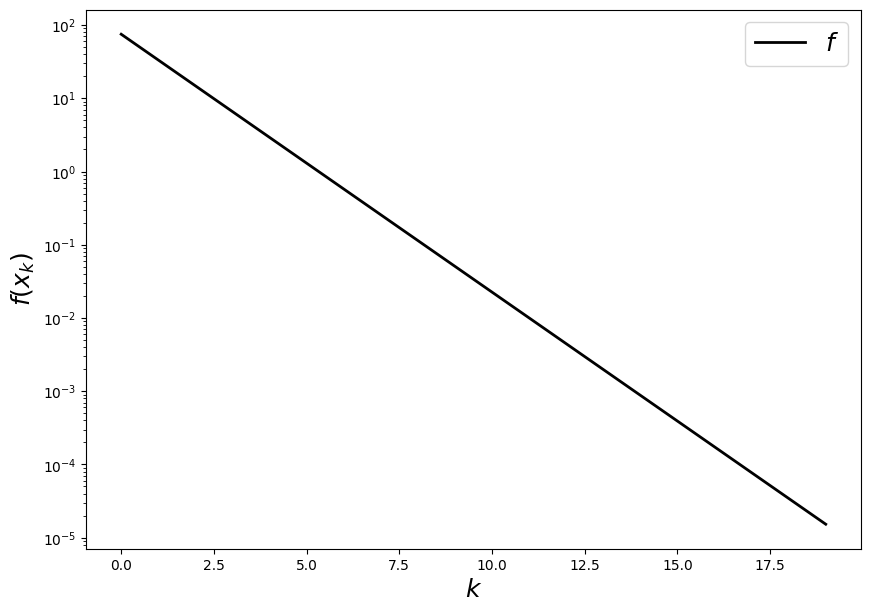

In [ ]:
plot_function_values(f_obs)

Per osservare il comportamento di gradient descent, possiamo definire una funzione per plottare la traiettoria.

In [ ]:
def plot_trajectory(x_obs, eta):
  bounds = [-7 , 7]
  x1 = np.linspace(bounds[0], bounds[1], 1000)
  x2 = np.linspace(bounds[0], bounds[1], 1000)

  X1, X2 = np.meshgrid(x1, x2)
  Y = (X1 ** 2 + eta * X2 ** 2) / 2

  fig, ax = plt.subplots(1, 1, figsize=(10, 7))
  ax.contour(X1, X2, Y, levels=20)

  x_prev = x_obs[0]
  for i in range(1, x_obs.shape[0]):
    x = np.clip(x_obs[i], [bounds[0], bounds[0]], [bounds[1], bounds[1]])
    ax.plot(x_prev[0], x_prev[1], 'o', c='black', ms=7)
    ax.annotate("", xy=(x[0], x[1]), xytext=(x_prev[0], x_prev[1]), arrowprops=dict(arrowstyle='->', ls='--', lw=2.0))
    x_prev = x

  ax.plot(0.0, 0.0, 'o', c='red')
  ax.set_xlabel("$x_1$", fontsize=18)
  ax.set_ylabel("$x_2$", fontsize=18)
  fig.tight_layout()



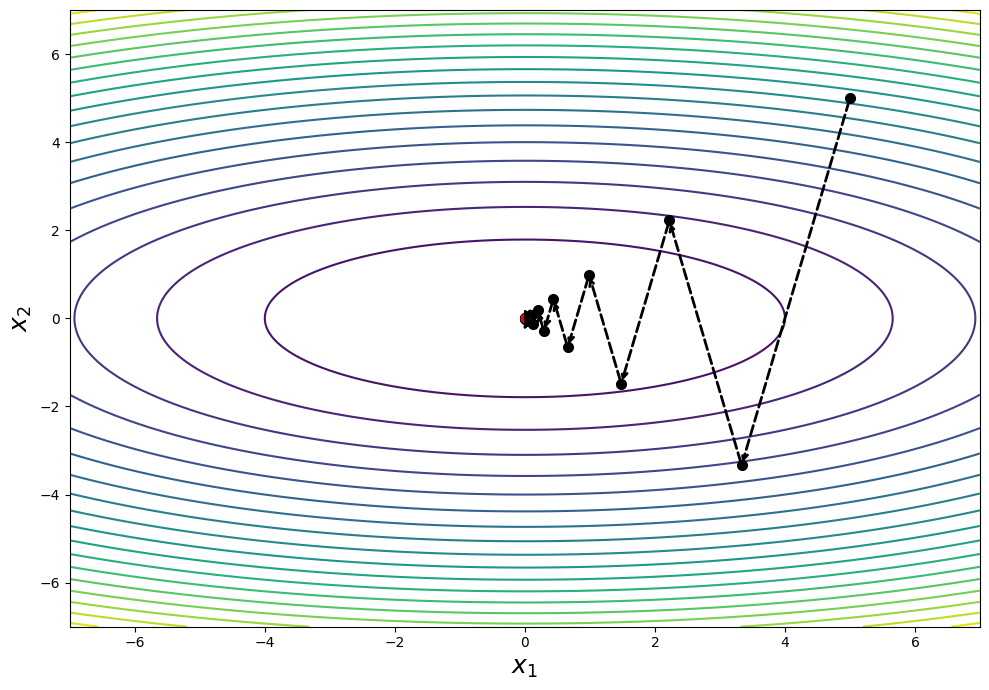

In [ ]:
plot_trajectory(x_obs, eta)

In [ ]:
  def plot_trajectory(x_obs, eta, f_vals):
    bounds = [-7 , 7]
    x1 = np.linspace(bounds[0], bounds[1], 1000)
    x2 = np.linspace(bounds[0], bounds[1], 1000)

    X1, X2 = np.meshgrid(x1, x2)
    Y = (X1 ** 2 + eta * X2 ** 2) / 2

    fig, (ax2,ax1) = plt.subplots(1, 2, figsize=(12, 6))
    ax1.contour(X1, X2, Y, levels=20)

    x_prev = x_obs[0]
    for i in range(1, x_obs.shape[0]):
      x = np.clip(x_obs[i], [bounds[0], bounds[0]], [bounds[1], bounds[1]])
      ax1.plot(x_prev[0], x_prev[1], 'o', c='black', ms=7)
      ax1.annotate("", xy=(x[0], x[1]), xytext=(x_prev[0], x_prev[1]), arrowprops=dict(arrowstyle='->', ls='--', lw=2.0))
      x_prev = x

    ax1.plot(0.0, 0.0, 'o', c='red')
    ax1.set_xlabel("$x_1$", fontsize=18)
    ax1.set_ylabel("$x_2$", fontsize=18)
    fig.tight_layout()

    ax2.plot(range(f_vals.shape[0]), f_vals, '-', color='black', lw=2, label="$f$")
    ax2.set_xlabel("$k$", fontsize=18)
    ax2.set_ylabel("$f(x_k)$", fontsize=18)
    ax2.set_yscale("log")
    ax2.legend(fontsize=18)


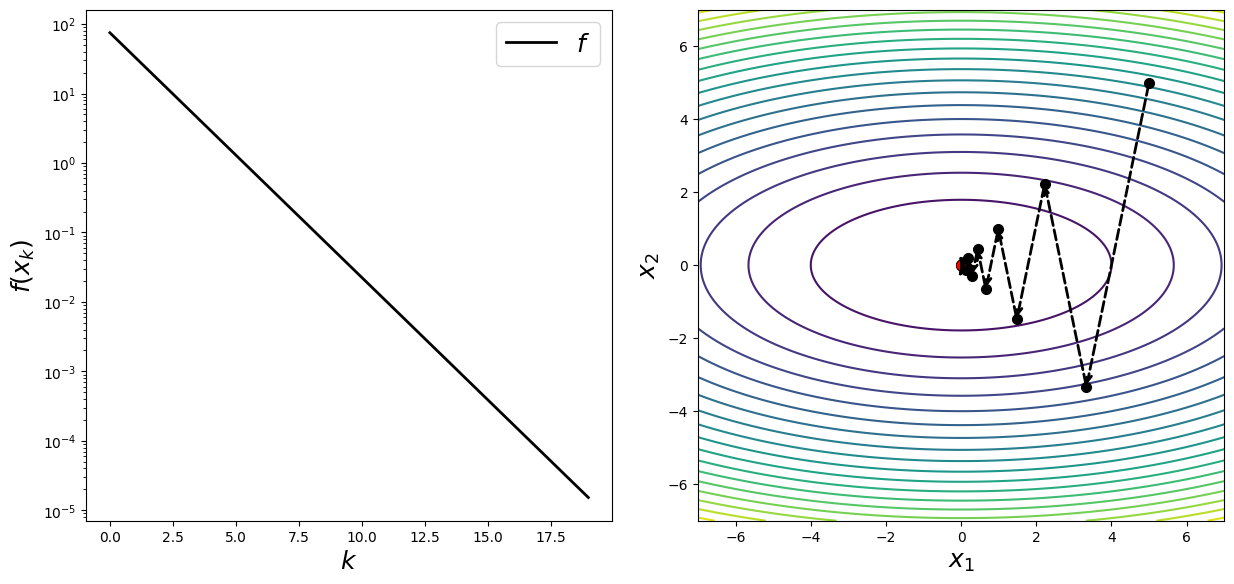

In [ ]:
plot_trajectory(x_obs, eta, f_obs)

Ora cambiamo lo stepsize e osserviamo come cambia la traiettoria

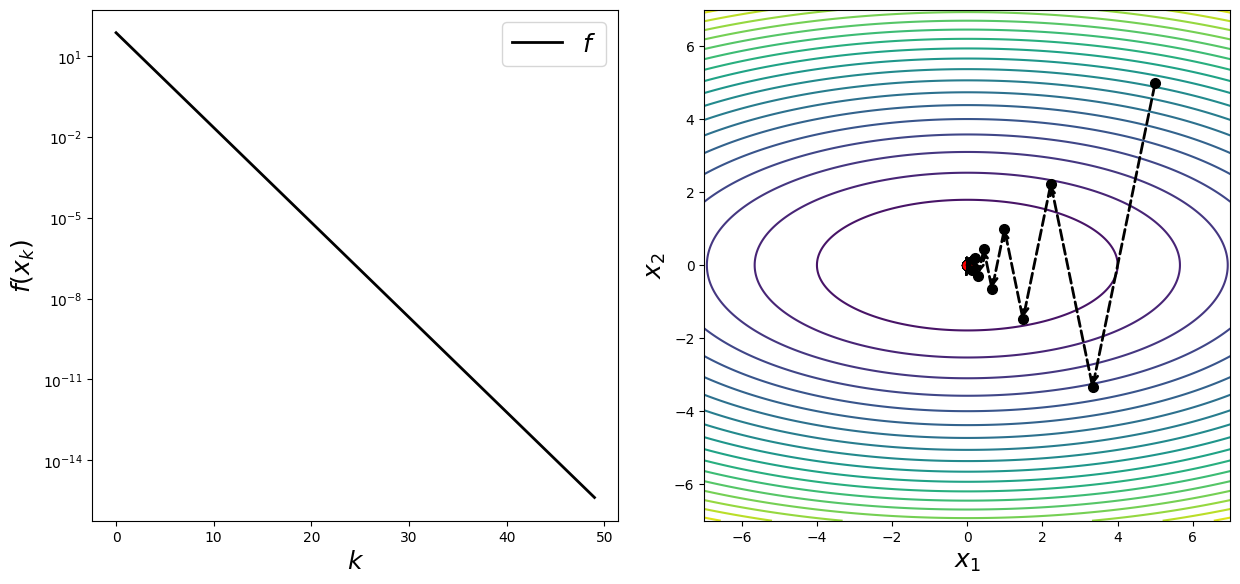

In [ ]:
gamma =2/(L+mu) # TODO: scegli uno stepsize per cui la convergenza e` garantita

# TODO: esegui gradient descent
x, x_obs, f_obs =gradient_descent(x0, eta, gamma, 50)

plot_trajectory(x_obs, eta, f_obs)

#plot_function_values(f_obs)
#plot_trajectory(x_obs, eta)

### Scelta dello stepsize
Ora, fissiamo un valore per $\eta > 1$ ed eseguiamo gradient descent per diversi stepsize (includi nella lista $\gamma = 2/(1 + \eta)$, $\gamma = 1/\eta$ e $\gamma = 2 / \eta$) e osserva come cambiano le performance

In [ ]:
eta = 5  # TODO: scegli un eta > 1

gammas = [2/(1+eta), 1/eta, 2/eta, 1/(L+mu), 1/(2*eta), 1/(5*eta), 1/(10*eta)] # TODO: definisci una lista di stepsize
gamma_labels = ["$2/(1+\\eta)$", "$1/\\eta$", "$2/\\eta$", "$1/(1+\\eta)$", "$1/(2\\eta)$", "$1/(5\\eta)$", "$1/(10\\eta)$"]

x0 = np.array([5.0, 5.0]) # inizializzazione
max_iters = 50 # numero massimo di iterazioni
f_values = []


for gamma in gammas:
  x, x_obs, f_obs = gradient_descent(x0, eta, gamma, max_iters) # TODO: esegui gradient descent
  f_values.append(f_obs)


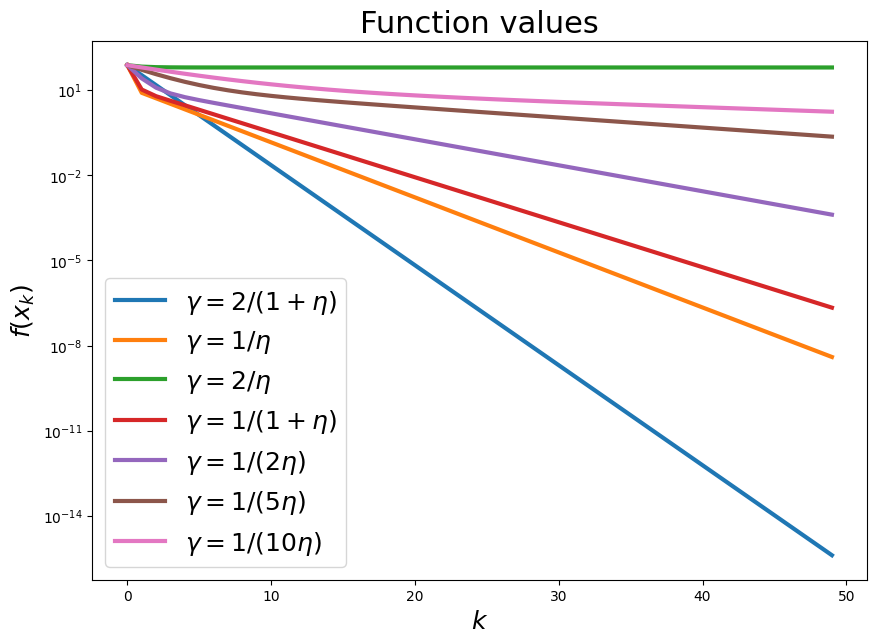

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 7))
ax.set_title("Function values", fontsize=22)
for i in range(len(gammas)):
  #ax.plot(range(f_values[i].shape[0]), f_values[i], '-', label="$\gamma = $" + str(round(gammas[i], 4)), lw=3)
  ax.plot(range(f_values[i].shape[0]), f_values[i], '-', label="$\gamma = $" + gamma_labels[i], lw=3)
ax.set_ylabel("$f(x_k)$", fontsize=18)
ax.set_xlabel("$k$", fontsize=18)
ax.set_yscale("log")
ax.legend(fontsize=18)

Ripetiamo l'esperimento e osserviamo che la seguente disuguaglianza e\` verificata



$$
\| x_k \| \leq q(\gamma)^k \| x_0 \| \qquad \text{dove} \qquad q(\gamma) = \left\{
        \begin{array}{ll}
            1 - \gamma & \quad \gamma \leq \frac{2}{\eta + 1} \\
            \gamma \eta - 1 & \quad \text{altrimenti}
        \end{array}
    \right.
$$
Plotta la norma di $x_k$ e $q(\gamma)^k \| x_0 \|$ per ogni $\gamma$


In [ ]:
eta = 5 # TODO: scegli un eta > 1

gammas = [1/(10 * eta), 1/(5 * eta),  1 / (2* eta), 1/eta, 1 / (1 + eta),  2 / (1 + eta), 2/eta, 2.0]
gamma_labels = [ "$1/(10\\eta)$", "$1/(5\\eta)$", "$1/(2\\eta)$", "$1/\\eta$", "$1/(1+\\eta)$",  "$2/(1+\\eta)$", "$2/\\eta$", "2"]

x0 = np.array([5.0, 5.0])
max_iters = 50

def q(gamma):
  # TODO: calcola e ritorna q(gamma)
  if gamma <= 2/(eta+1):
    return 1-gamma
  else:
    return gamma*eta-1

def norm_upper_bound(x0, gamma, max_iters):
  ub = np.zeros(max_iters)
  q_gamma = q(gamma)
  x0_norm = norm(x0)
  for k in range(max_iters):
    ub[k] = pow(q_gamma,k)*x0_norm  # TODO: calcola q(gamma)^k || x_0 ||
  return ub



x_norms = []
upper_bounds = []

for gamma in gammas:
  ub =norm_upper_bound(x0,gamma,max_iters) # TODO: calcola la norma dell' upper bound
  x, x_obs, f_obs = gradient_descent(x0, eta, gamma, max_iters) # TODO: esegui gradient descent
  x_norms.append(norm(x_obs, axis=1))
  upper_bounds.append(ub)




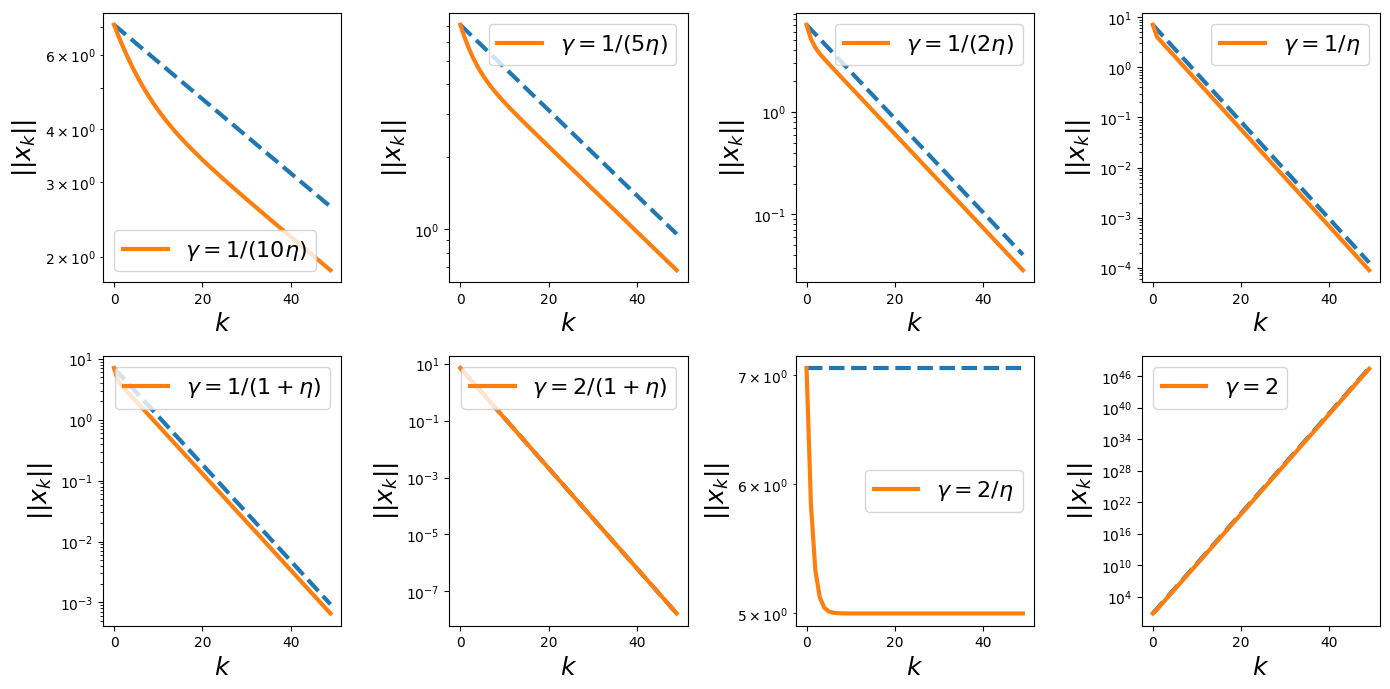

In [ ]:

num_rows = 2
num_cols = 4

fig, axs = plt.subplots(num_rows, num_cols, figsize=(14, 7))

c = 0
for i in range(num_rows):
  for j in range(num_cols):
    axs[i][j].plot(range(upper_bounds[c].shape[0]), upper_bounds[c], '--', lw=3)
    #axs[i][j].plot(range(x_norms[c].shape[0]), x_norms[c], '-', label="$\gamma = $" + str(round(gammas[c], 4)), lw=3)
    axs[i][j].plot(range(x_norms[c].shape[0]), x_norms[c], '-', label="$\gamma = $" + gamma_labels[c], lw=3)

    axs[i][j].set_ylabel("$|| x_k ||$", fontsize=18)
    axs[i][j].set_xlabel("$k$", fontsize=18)
    axs[i][j].set_yscale("log")
    axs[i][j].legend(fontsize=16)
    c+= 1
fig.tight_layout()

## Least Square Problem
Siano $A \in \mathbb{R}^{n \times d}$ e $y \in \mathbb{R}^n$, consideriamo il seguente problema di minimizzazione
$$
x^* \in \arg\min f(x) := \frac{1}{2} \| Ax - y \|^2.
$$
Consideriamo il setting $n > d$ dove la funzione e\` $\mu$-fortemente convessa e  gradient descent con  $\gamma = 2/(L + \mu)$ ha il seguente rate di convergenza

$$
\| x_k - x^* \| \leq\Big( \frac{L - \mu}{L + \mu} \Big)^k \| x_0 - x^* \|
$$

Implementiamo la funzione target e il sup gradiente

In [ ]:
def f2(x):
  return 0.5 * np.square(norm(A @ x - y))

def grad_f2(x):
  # TODO: ritorna il gradiente di f in x
  return np.transpose(A)@(A @ x - y)


Istanziamo una matrice casuale $A \in \mathbb{R}^{n \times d}$ in cui le ogni entrata $A_{i,j} \sim \mathcal{N}(0, 1)$ e un vettore $y \in \mathbb{R}^n$

In [ ]:
n = 100
d = 10

x_star = np.ones(d)

A = np.random.randn(n, d) # Genera una matrice n x d in cui ogni entrata e` ~ N(0, 1)
y = A @ x_star

Reimplementiamo gradient descent. Nello specifico, implementiamo la seguente funzione

```
gd(x0, gamma, f, grad_f, max_iters)
```
dove:
- `x0` e\` un numpy array che rappresenta l'inizializzazione.
- `gamma` e\` lo stepsze.
- `f` e\` la funzione target.
- `grad_f` e\` la funzione che ritorna il gradiente della funzione target.
- `max_iters` e\` il numero di iterazioni.

La funzione ritornera\` tre elementi:
- `x`: l'ultima iterata
- `x_obs` : una matrice (max_iters $\times$ d) contenente tutte le iterate
- `f_obs` : un vettore contenente i function values sulle iterate (i.e. $f(x_k)$ for $k=1, \cdots, $max_iters)


In [ ]:
def gd(x0, gamma, f, grad_f, max_iters = 10):
  x = x0.copy()
  x_obs = np.empty((max_iters, x0.shape[0]))
  f_obs = np.empty(max_iters)
  for k in range(max_iters):
    x_obs[k] = x
    f_obs[k] = f(x)
    x = x - gamma*grad_f(x) # TODO: implementa l'iterazione di gradient descent
  return x, x_obs, f_obs


Ora usiamo l'algoritmo per risolvere il problema

In [ ]:
x0 = np.full((d,), 5.0) # inizializzazione
max_iters = 50 # numero di iterazioni

AtA = np.dot(np.transpose(A),A)
eigenvalues =np.linalg.eigvalsh(AtA)
mu=np.min(eigenvalues)
#L=norm(AtA)
L=np.max(eigenvalues)
gamma=2/(mu+L)  # TODO: calcola gamma


x, x_obs, f_vals = gd(x0, gamma, f2, grad_f2, max_iters) # TODO: esegui gradient descent
x_norms = norm(x_obs - x_star, axis=1) # calcola ||x_k - x^*||


Ora, possiamo plottare i function values e la norma delle iterazioni

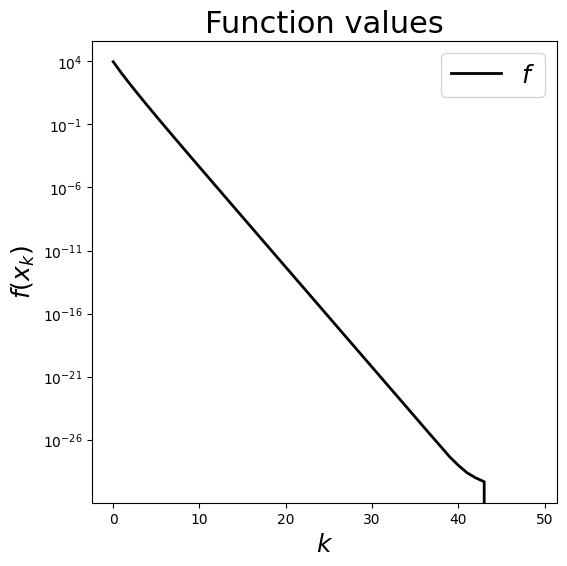

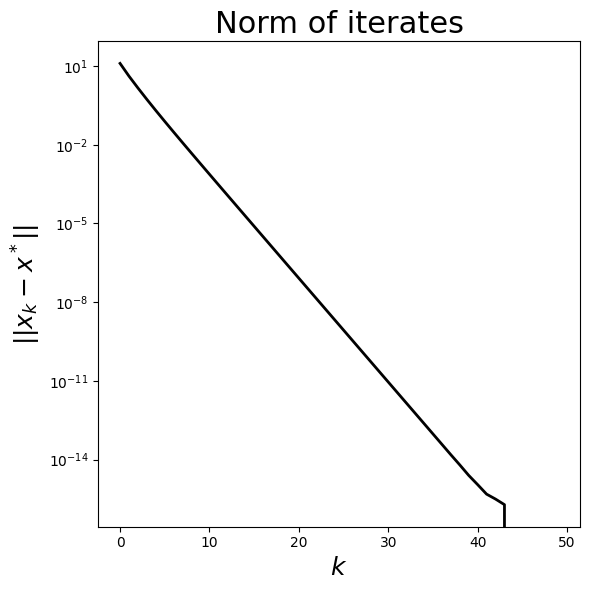

In [ ]:
fig, ax1= plt.subplots(1, 1, figsize=(6, 6))
ax1.plot(range(f_vals.shape[0]), f_vals, '-', color='black', lw=2, label="$f$")
ax1.set_xlabel("$k$", fontsize=18)
ax1.set_ylabel("$f(x_k)$", fontsize=18)
ax1.set_yscale("log")
ax1.legend(fontsize=18)
ax1.set_title("Function values", fontsize=22)

fig, ax2= plt.subplots(1, 1, figsize=(6, 6))
ax2.set_title("Norm of iterates", fontsize=22)
ax2.plot(range(x_norms.shape[0]), x_norms, '-', color='black', lw=2)
ax2.set_xlabel("$k$", fontsize=18)
ax2.set_ylabel("$|| x_k - x^* ||$", fontsize=18)
ax2.set_yscale("log")
fig.tight_layout()


Cambia lo stepsize e osserva come cambiano le performance

In [ ]:
# TODO: calcola gamma

gamma=2/(mu+L)


x, x_obs, f_vals =gd(x0, gamma, f2, grad_f2, max_iters)  # TODO: esegui Gradient Descent
x_norms = norm(x_obs - x_star, axis=1)

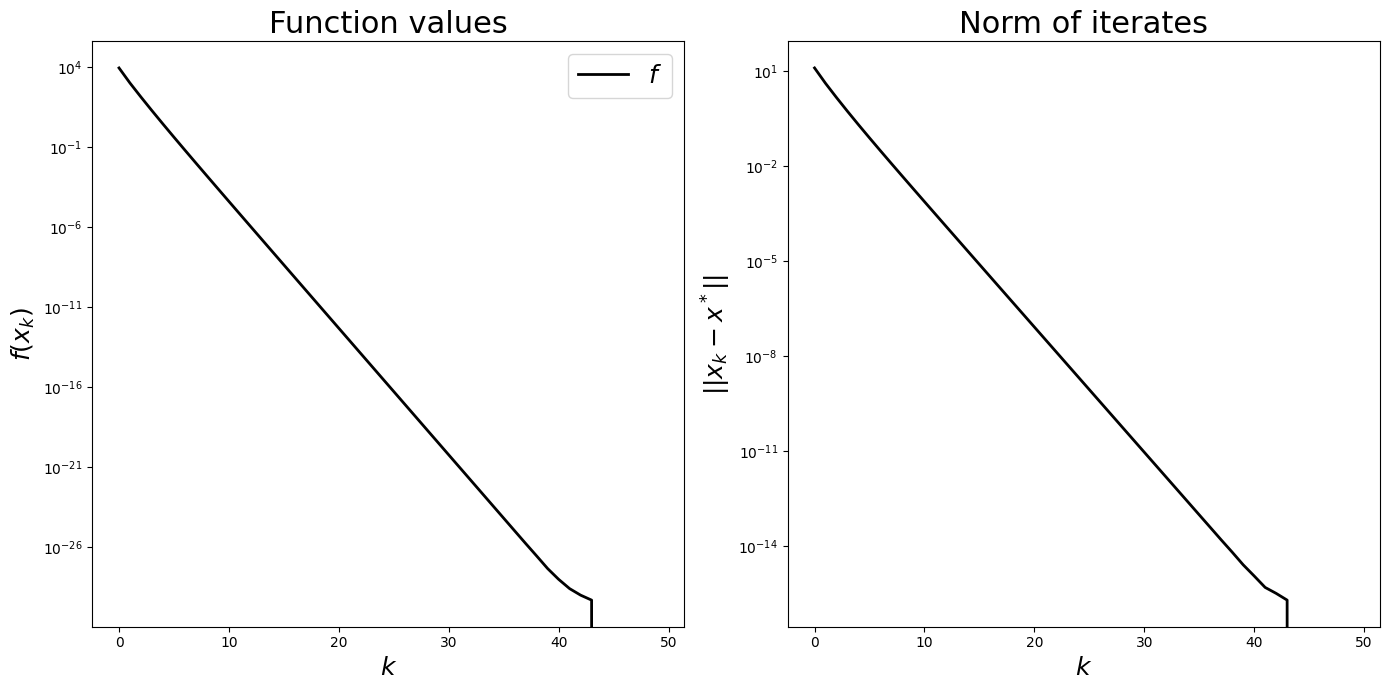

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
ax1.plot(range(f_vals.shape[0]), f_vals, '-', color='black', lw=2, label="$f$")
ax1.set_xlabel("$k$", fontsize=18)
ax1.set_ylabel("$f(x_k)$", fontsize=18)
ax1.set_yscale("log")
ax1.legend(fontsize=18)
ax1.set_title("Function values", fontsize=22)

ax2.set_title("Norm of iterates", fontsize=22)
ax2.plot(range(x_norms.shape[0]), x_norms, '-', color='black', lw=2)
ax2.set_xlabel("$k$", fontsize=18)
ax2.set_ylabel("$|| x_k - x^* ||$", fontsize=18)
ax2.set_yscale("log")
fig.tight_layout()


In [ ]:
x0 = np.full((d,), 5.0) # inizializzazione
max_iters = 50 # numero di iterazioni

AtA=np.dot(np.transpose(A),A)
eigenvalues=np.linalg.eigvalsh(AtA)
mu=np.min(eigenvalues)
#L=norm(AtA)
L=np.max(eigenvalues)

gammas = [1/(10 * L), 1/(5 * L), 1/(2 * L), 1/(L), 1/(L+mu), 2/(L+mu), 2/L]
gamma_labels = ["$1/(10*L)$", "$1/(5*L)$", "$1/(2*L)$", "$1/L$", "$1/(L+\\mu)$", "$2/(L+\\mu)$", "$2/L$"]
fun_values = []

for gamma in gammas:
  x, x_obs, f_vals =gd(x0, gamma, f2, grad_f2, max_iters) # TODO: esegui gradient descent
  fun_values.append(f_vals)

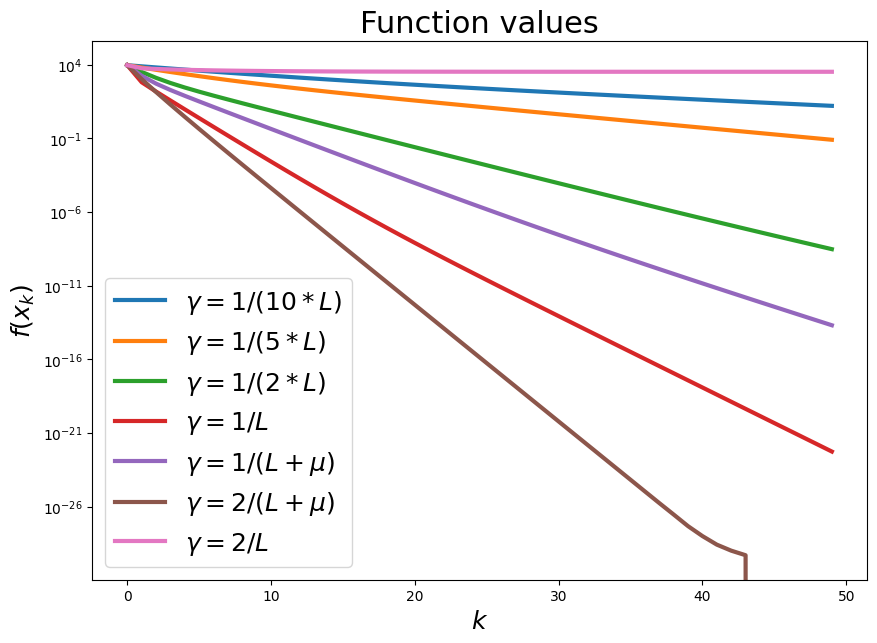

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 7))
ax.set_title("Function values", fontsize=22)
for i in range(len(gammas)):
  #ax.plot(range(fun_values[i].shape[0]), fun_values[i], '-', label="$\gamma = $" + str(round(gammas[i], 4)), lw=3)
  ax.plot(range(fun_values[i].shape[0]), fun_values[i], '-', label="$\gamma = $" + gamma_labels[i], lw=3)
ax.set_ylabel("$f(x_k)$", fontsize=18)
ax.set_xlabel("$k$", fontsize=18)
ax.set_yscale("log")
ax.legend(fontsize=18)

Generiamo una matrice $A \in \mathbb{R}^{n \times d}$ casuale con entrate Gaussiane con $n = 50$ e $d= 100$.

Sia ̄$\bar{x} \in \mathbb{R}^{d}$ e definiamo $y=A\bar{x}$. Consideriamo il problema

$$
x^* \in \arg\min f(x) := \frac{1}{2} \| Ax - y \|^2.
$$

In questo caso la funzione non e\` fortemente convessa. Tuttavia, gradient descent converge con il seguente rate

\begin{equation}
f(x_k) - \min f \leq (1 - \gamma \lambda_{min} (2 - \gamma L) )^k (f(x_0) - \min f)
\end{equation}

Verifica la convergenza lineare


In [ ]:
n, d = 50, 100

A = np.random.randn(n, d) # generiamo la matrice

x_bar = np.ones(d) # fissiamo x^*
y = A @ x_bar # calcoliamo y = Ax^*

In [ ]:
x0 = np.full((d,), 5.0)

AtA=np.dot(np.transpose(A),A)
L=norm(AtA)
L=np.max(np.linalg.eigvalsh(AtA))
gamma=1/(L)# TODO: calcola gamma

max_iters= 1000


x, x_obs, f_obs =gd(x0, gamma, f2, grad_f2, max_iters) # TODO: esegui gradient descent
x_norms = norm(x_obs - x_bar, axis=1) # calcola ||x_k - x^*||


Plottiamo i function values

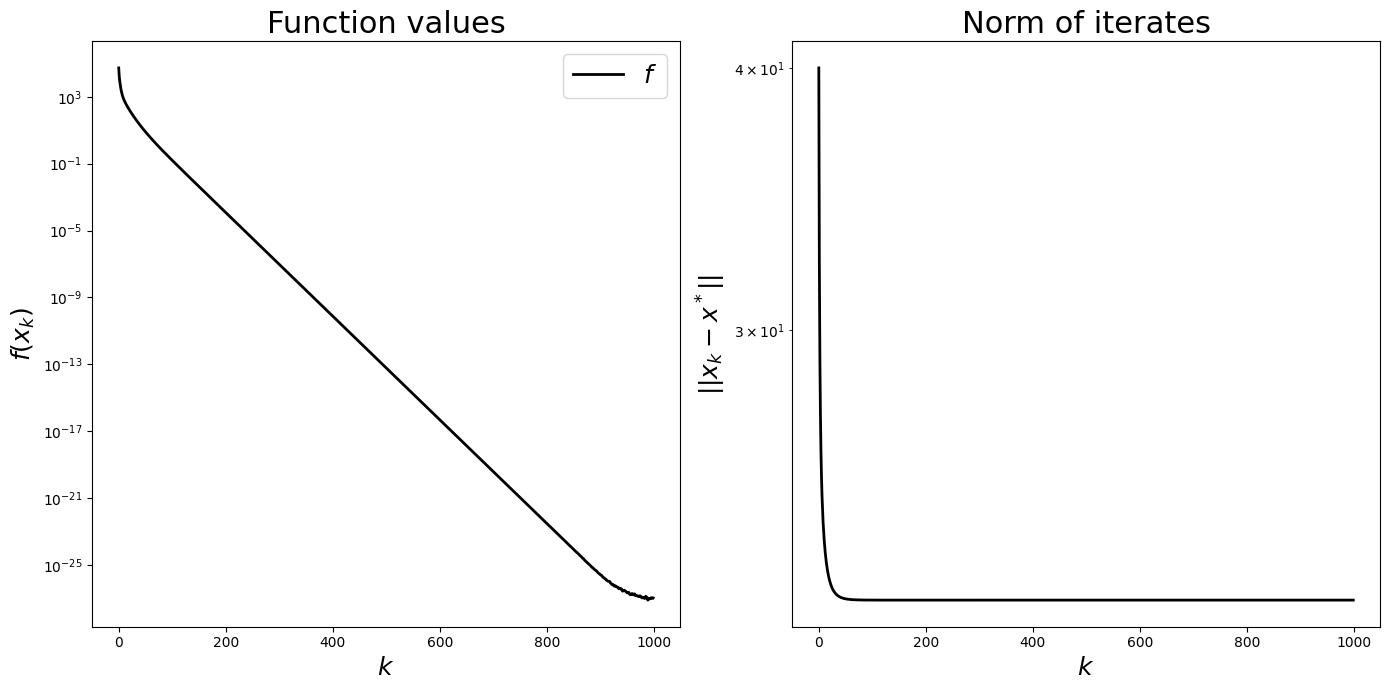

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
ax1.plot(range(f_obs.shape[0]), f_obs, '-', color='black', lw=2, label="$f$")
ax1.set_xlabel("$k$", fontsize=18)
ax1.set_ylabel("$f(x_k)$", fontsize=18)
ax1.set_yscale("log")
ax1.legend(fontsize=18)
ax1.set_title("Function values", fontsize=22)

ax2.set_title("Norm of iterates", fontsize=22)
ax2.plot(range(x_norms.shape[0]), x_norms, '-', color='black', lw=2)
ax2.set_xlabel("$k$", fontsize=18)
ax2.set_ylabel("$|| x_k - x^* ||$", fontsize=18)
ax2.set_yscale("log")
fig.tight_layout()

Ripeti l'esperimento per i seguenti valori di gamma e osserva come $f(x_k)$ cambia.

In [ ]:
AtA=np.dot(np.transpose(A),A)
eigenvalues=np.linalg.eigvalsh(AtA)
sigma_min=np.min(eigenvalues)

gammas = [1/(10 * L), 1/(5 * L), 1/(3 * L), 1/(2 * L), 1/L, 2/(L+sigma_min)]
gamma_labels = ["$1/(10*L)$", "$1/(5*L)$", "$1/(3*L)$", "$1/(2*L)$", "$1/L$", "$2/(L+\\sigma_{min})$"]
fun_values = []

for gamma in gammas:
  x, x_obs, f_vals =gd(x0, gamma, f2, grad_f2, max_iters) # TODO: esegui gradient descent
  fun_values.append(f_vals)


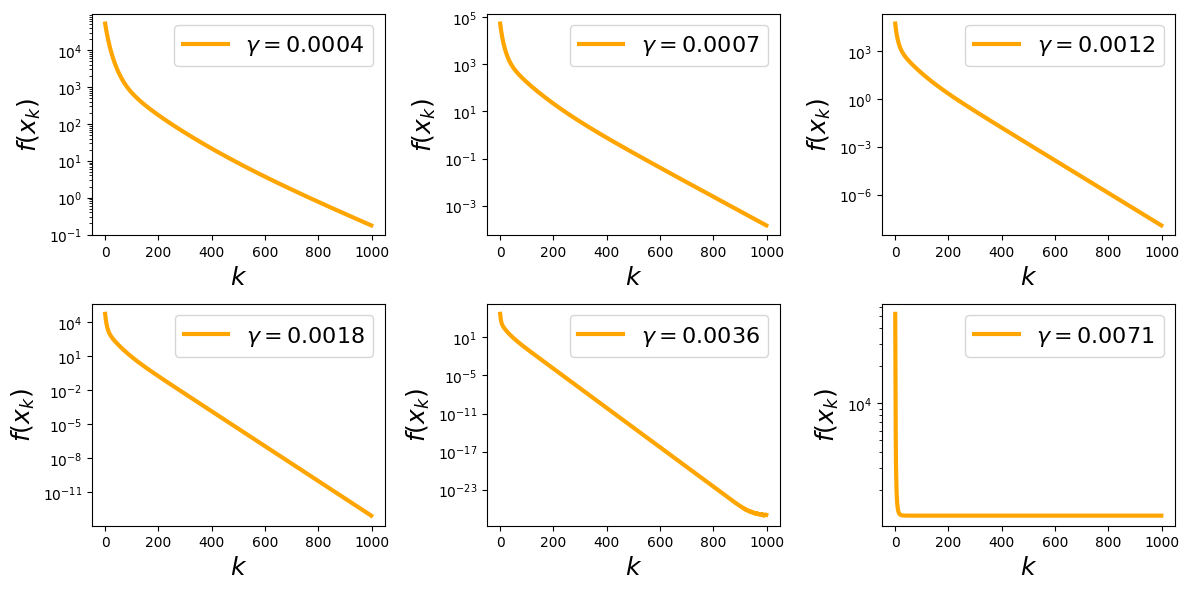

In [ ]:

num_rows = 2
num_cols = 3

fig, axs = plt.subplots(num_rows, num_cols, figsize=(12, 6))

c = 0
for i in range(num_rows):
  for j in range(num_cols):
    axs[i][j].plot(range(fun_values[c].shape[0]), fun_values[c], '-', c='orange', label="$\gamma = $" + str(round(gammas[c], 4)), lw=3)

    axs[i][j].set_ylabel("$f(x_k)$", fontsize=18)
    axs[i][j].set_xlabel("$k$", fontsize=18)
    axs[i][j].set_yscale("log")
    axs[i][j].legend(fontsize=16)
    c+= 1
fig.tight_layout()

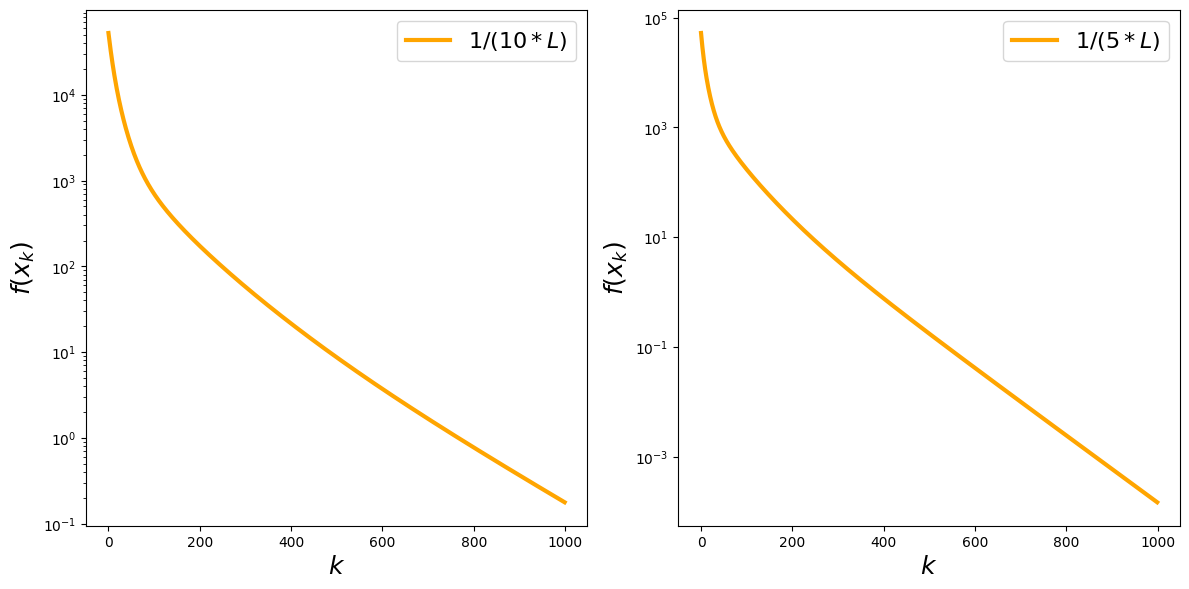

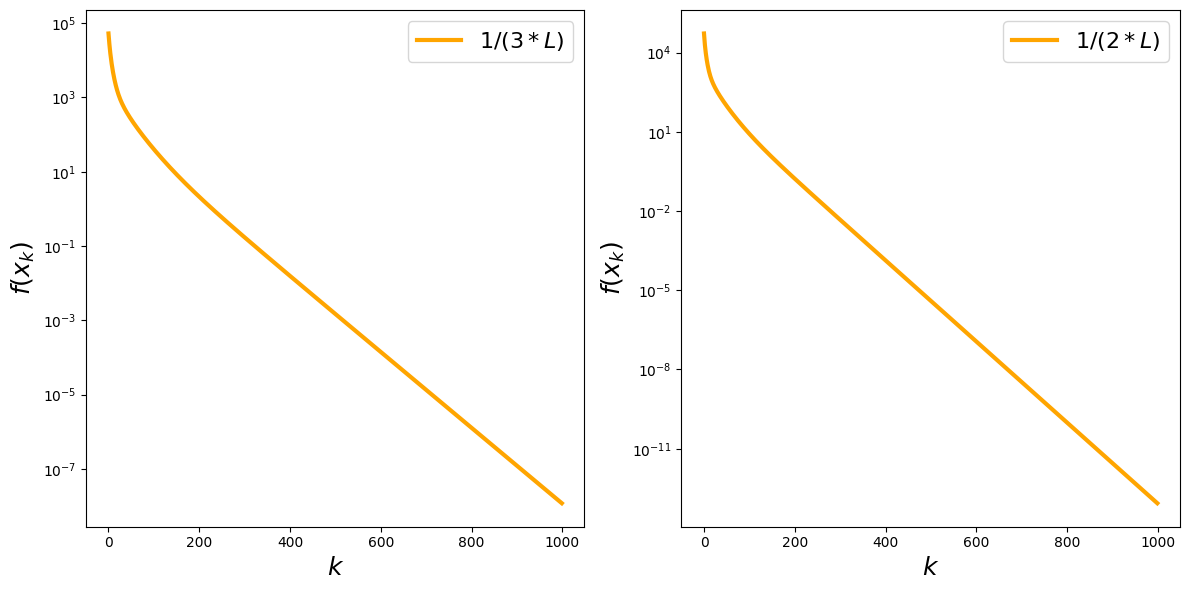

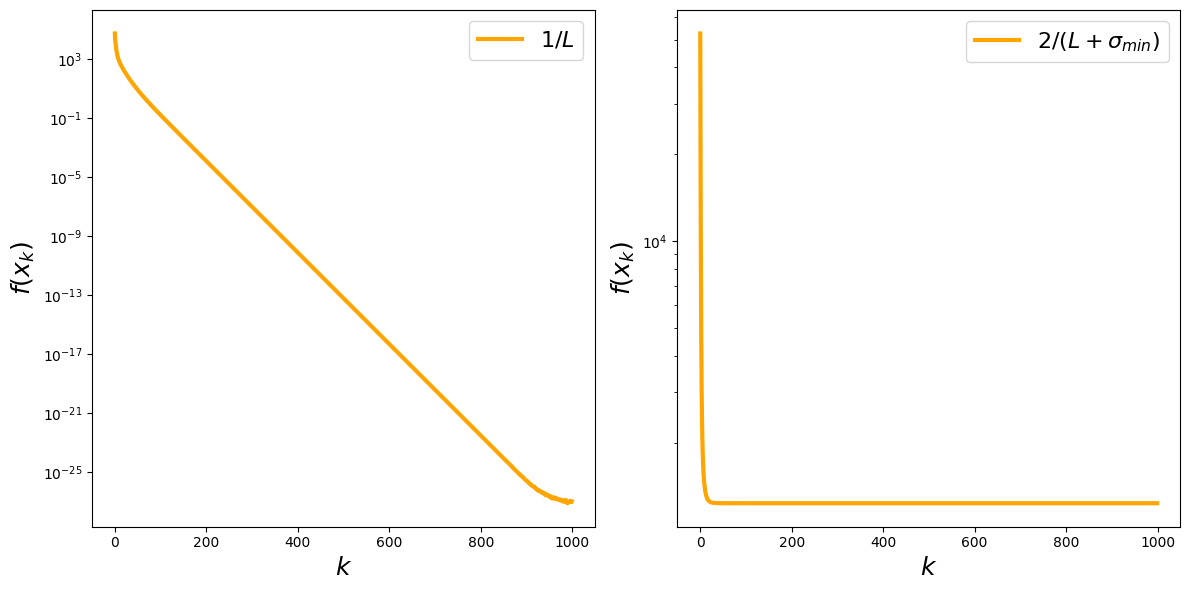

In [ ]:
num_rows = 1  # Set to 1 row
num_cols = 2  # Set to 2 columns

# Loop through each group of two gammas
for i in range(0, len(gammas), 2):
    fig, axs = plt.subplots(num_rows, num_cols, figsize=(12, 6))

    for j in range(num_cols):
        gamma_idx = i + j
        if gamma_idx < len(gammas):
            #axs[j].plot(range(fun_values[gamma_idx].shape[0]), fun_values[gamma_idx], '-', c='orange', label="$\gamma = $" + str(round(gammas[gamma_idx], 4)), lw=3)
            axs[j].plot(range(fun_values[gamma_idx].shape[0]), fun_values[gamma_idx], '-', c='orange', label=gamma_labels[gamma_idx], lw=3)


            axs[j].set_ylabel("$f(x_k)$", fontsize=18)
            axs[j].set_xlabel("$k$", fontsize=18)
            axs[j].set_yscale("log")
            axs[j].legend(fontsize=16)

    fig.tight_layout()
    plt.show()  # Show each figure separately


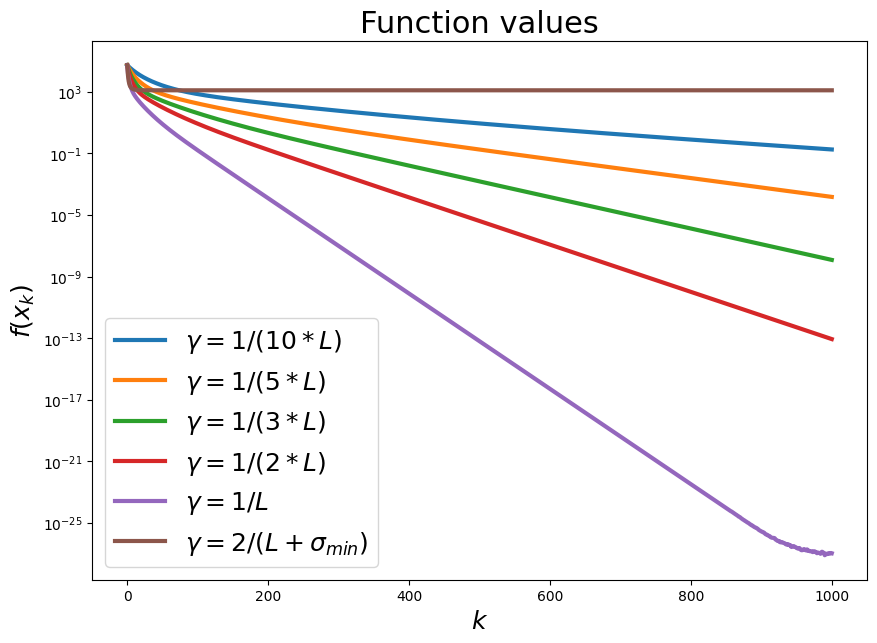

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 7))
ax.set_title("Function values", fontsize=22)
for i in range(len(gammas)):
  #ax.plot(range(fun_values[i].shape[0]), fun_values[i], '-', label="$\gamma = $" + str(round(gammas[i], 4)), lw=3)
  ax.plot(range(fun_values[i].shape[0]), fun_values[i], '-', label="$\gamma = $" + gamma_labels[i], lw=3)
ax.set_ylabel("$f(x_k)$", fontsize=18)
ax.set_xlabel("$k$", fontsize=18)
ax.set_yscale("log")
ax.legend(fontsize=18)